#  Building (Example5)

![gallery_thumbnail](img/Example5.svg)

## Modeling

Begin by creating {ref}`units <Units>`:

In [ ]:
from xara.units import create_units

units = create_units(system="iks")

inch = units.inch 
foot = units.foot
ksi  = units.ksi
kip  = units.kip

### Materials


In [ ]:
import xara
import math

# CONCRETE
Fcov = -4.0
Fcuv =  0.0
ecov = -0.002
ecuv = -0.006

Fcoc = -5.0
Fcuc = -3.5
ecoc = -0.005
ecuc = -0.020
Ec = 57000.0*math.sqrt(abs(Fcov*1000.0))/1000.0


# STEEL
Fy =    60.0;    # Yield stress
Es = 30000.0;    # Young's modulus
materials = {
    "steel": xara.UniaxialMaterial("Steel01", 
                                    Fy=Fy, 
                                    E=Es,
                                    b=0.02),
    # "cover": xara.UniaxialMaterial("Concrete01",
    #                                Fc=Fcov),
    # "core":  xara.UniaxialMaterial("Concrete01",
    #                                Fc=Fcoc)
}


In [2]:

#

def ReinforcedRectangle(model, 
                        id, 
                        h, b,
                        cover, 
                        coreID, coverID, steelID, 
                        numBars, barArea, 
                        nfCoreY, nfCoreZ, nfCoverY, nfCoverZ,
                        GJ):
    r"""
    Define a procedure which generates a rectangular reinforced concrete section
    with one layer of steel evenly distributed around the perimeter and a confined core.

                          y
                          |
                          |
                          |
                ---------------------
                |\                 /|
                | \---------------/ |
                | |               | |
                | |               | |
     z ---------| |               | |  h
                | |               | |
                | |               | |
                | /---------------\ |
                |/                 \|
                ---------------------
                          b

    Arguments
       id - tag for the section that is generated by this procedure
       h - overall height of the section (see above)
       b - overall width of the section (see above)
       cover - thickness of the cover patches
       coreID - material tag for the core patch
       coverID - material tag for the cover patches
       steelID - material tag for the reinforcing steel
       numBars - number of reinforcing bars on any given side of the section
       barArea - cross-sectional area of each reinforcing bar
       nfCoreY - number of fibers in the core patch in the y direction
       nfCoreZ - number of fibers in the core patch in the z direction
       nfCoverY - number of fibers in the cover patches with long sides in the y direction
       nfCoverZ - number of fibers in the cover patches with long sides in the z direction

    Notes
       The thickness of cover concrete is constant on all sides of the core.
       The number of bars is the same on any given side of the section.
       The reinforcing bars are all the same size.
       The number of fibers in the short direction of the cover patches is set to 1.

    """

    # The distance from the section z-axis to the edge of the cover concrete
    # in the positive y direction
    coverY = h/2.0

    # The distance from the section y-axis to the edge of the cover concrete
    # in the positive z direction
    coverZ = b/2.0

    # Determine the corresponding values from the respective axes to the
    # edge of the core concrete
    coreY = coverY - cover
    coreZ = coverZ - cover

    # Define the fiber section
    model.section("Fiber", id, GJ=GJ)

    # Define the core patch
    model.patch("quad", coreID, nfCoreZ, nfCoreY, 
                -coreY, coreZ, -coreY, -coreZ, coreY, -coreZ, coreY, coreZ)

    # Define the four cover patches
    model.patch("quad", coverID, 1,        nfCoverY, -coverY,  coverZ, -coreY,   coreZ,   coreY,   coreZ,   coverY,  coverZ)
    model.patch("quad", coverID, 1,        nfCoverY, -coreY,  -coreZ,  -coverY, -coverZ,  coverY, -coverZ,  coreY,  -coreZ)
    model.patch("quad", coverID, nfCoverZ, 1,        -coverY,  coverZ, -coverY, -coverZ, -coreY,  -coreZ,  -coreY,   coreZ)
    model.patch("quad", coverID, nfCoverZ, 1,         coreY,   coreZ,   coreY,  -coreZ,   coverY, -coverZ,  coverY,  coverZ)

    # Define the steel along constant values of y (in the z direction)
    model.layer("straight", steelID, numBars, barArea, -coreY, coreZ, -coreY, -coreZ)
    model.layer("straight", steelID, numBars, barArea,  coreY, coreZ,  coreY, -coreZ)

    # Determine the spacing for the remaining bars in the y direction
    spacingY = (2.0*coreY)/(numBars-1)

    # Avoid double counting bars
    numBars = numBars-2

    # Define remaining steel in the y direction
    model.layer("straight", steelID, numBars, barArea, coreY-spacingY,  coreZ, (-coreY+spacingY),  coreZ)
    model.layer("straight", steelID, numBars, barArea, coreY-spacingY, -coreZ, (-coreY+spacingY), -coreZ)



### Model

In [3]:
def create_model(column_element=None, 
                 column_geometry="Linear"):

    if column_element is None:
        column_element = "forceBeamColumn"


    # create Model in three-dimensions with 6 DOF/node
    model = xara.Model(ndm=3, ndf=6)

    # Define materials for nonlinear columns
    # --------------------------------------

    # Core concrete (confined)
    #                                 tag  f'c   epsc0  f'cu  epscu
    model.uniaxialMaterial("Concrete01", 1, Fcoc, ecoc, Fcuc, ecuc)

    # Cover concrete (unconfined)
    #                                 tag  f'c   epsc0  f'cu  epscu
    model.uniaxialMaterial("Concrete01", 2, Fcov, ecov, Fcuv, ecuv)

    # STEEL
    # Reinforcing steel 
    model.uniaxialMaterial("Steel01", 3, Fy, Es, 0.02)



    # Geometry
    # ---------------

    # Set parameters for model geometry
    h  = 144.0;      # Story height
    by = 240.0;      # Bay width in Y-direction
    bx = 240.0;      # Bay width in X-direction

    # Create nodes
    #            tag    X        Y       Z 
    model.node( 1, (-bx/2.0,  by/2.0,   0.0))
    model.node( 2, ( bx/2.0,  by/2.0,   0.0))
    model.node( 3, ( bx/2.0, -by/2.0,   0.0))
    model.node( 4, (-bx/2.0, -by/2.0,   0.0))

    model.node( 5, (-bx/2.0,  by/2.0,     h))
    model.node( 6, ( bx/2.0,  by/2.0,     h))
    model.node( 7, ( bx/2.0, -by/2.0,     h))
    model.node( 8, (-bx/2.0, -by/2.0,     h))

    model.node(10, (-bx/2.0,  by/2.0, 2.0*h))
    model.node(11, ( bx/2.0,  by/2.0, 2.0*h))
    model.node(12, ( bx/2.0, -by/2.0, 2.0*h))
    model.node(13, (-bx/2.0, -by/2.0, 2.0*h))

    model.node(15, (-bx/2.0,  by/2.0, 3.0*h))
    model.node(16, ( bx/2.0,  by/2.0, 3.0*h))
    model.node(17, ( bx/2.0, -by/2.0, 3.0*h))
    model.node(18, (-bx/2.0, -by/2.0, 3.0*h))

    # Retained nodes for rigid diaphragm
    #        tag    ( X    Y    Z   )
    model.node( 9,  (0.0, 0.0,     h))
    model.node(14,  (0.0, 0.0, 2.0*h))
    model.node(19,  (0.0, 0.0, 3.0*h))

    # Set base constraints
    #      tag DX DY DZ RX RY RZ
    model.fix(1, (1, 1, 1, 1, 1, 1))
    model.fix(2, (1, 1, 1, 1, 1, 1))
    model.fix(3, (1, 1, 1, 1, 1, 1))
    model.fix(4, (1, 1, 1, 1, 1, 1))

    # Define rigid diaphragm multi-point constraints
    #              normalDir retained constrained
    model.rigidDiaphragm(3,  9,  5,  6,  7,  8)
    model.rigidDiaphragm(3, 14, 10, 11, 12, 13)
    model.rigidDiaphragm(3, 19, 15, 16, 17, 18)

    # Constraints for rigid diaphragm retained nodes
    #        tag  (DX DY DZ RX RY RZ)
    model.fix( 9, ( 0, 0, 1, 1, 1, 0))
    model.fix(14, ( 0, 0, 1, 1, 1, 0))
    model.fix(19, ( 0, 0, 1, 1, 1, 0))

    # Column parameters
    h  = 18.0
    GJ = 1.0e10
    colSec = 1

    # Call the RCsection procedure to generate the column section
    ReinforcedRectangle(model, colSec, 
                        h, h, 
                        cover=2.5, 
                        coreID=1,
                        coverID=2,
                        steelID=3,
                        numBars=3,
                        barArea=0.79,
                        nfCoreY=8,
                        nfCoreZ=8,
                        nfCoverY=10,
                        nfCoverZ=10,
                        GJ=GJ)

    #
    #  Define material properties for elastic beams
    #
    # Using beam depth of 24 and width of 18
    Abeam = 18.0*24.0
    # "Cracked" second moments of area
    Ibeamzz = 0.5*1.0/12.0*18.0*(24.0**3)
    Ibeamyy = 0.5*1.0/12.0*24.0*(18.0**3)

    # Define elastic section for beams
    girder_section = 2
    #                       tag     E    A      Iz       Iy     G    J
    model.section("Elastic", girder_section, Ec, Abeam, Ibeamzz, Ibeamyy, GJ, 1.0)

    # Define column elements
    # ----------------------

    # Geometric transformation for columns
    model.geomTransf(column_geometry, 1, (1.0, 0.0, 0.0))

    # Number of column integration points (sections)
    np  = 4
    itg = 1
    model.beamIntegration("Lobatto", itg, colSec, np)


    #                   tag ndI ndJ transfTag integrationTag
    model.element(column_element,  1, ( 1,  5), 1, itg)
    model.element(column_element,  2, ( 2,  6), 1, itg)
    model.element(column_element,  3, ( 3,  7), 1, itg)
    model.element(column_element,  4, ( 4,  8), 1, itg)

    model.element(column_element,  5, ( 5, 10), 1, itg)
    model.element(column_element,  6, ( 6, 11), 1, itg)
    model.element(column_element,  7, ( 7, 12), 1, itg)
    model.element(column_element,  8, ( 8, 13), 1, itg)

    model.element(column_element,  9, (10, 15), 1, itg)
    model.element(column_element, 10, (11, 16), 1, itg)
    model.element(column_element, 11, (12, 17), 1, itg)
    model.element(column_element, 12, (13, 18), 1, itg)

    # Define beam elements
    # --------------------

    # Geometric transformation for beams
    model.geomTransf("Linear", 2, 1.0, 1.0, 0.0)

    # Number of beam integration points (sections)
    np = 3
    model.beamIntegration("Lobatto", girder_section, girder_section, np)

    # Create the beam elements
    #                   tag (ndI ndJ) transfTag section
    girder_element = "forceBeamColumn"
    model.element(girder_element, 13, ( 5,  6), 2, girder_section)
    model.element(girder_element, 14, ( 6,  7), 2, girder_section)
    model.element(girder_element, 15, ( 7,  8), 2, girder_section)
    model.element(girder_element, 16, ( 8,  5), 2, girder_section)

    model.element(girder_element, 17, (10, 11), 2, girder_section)
    model.element(girder_element, 18, (11, 12), 2, girder_section)
    model.element(girder_element, 19, (12, 13), 2, girder_section)
    model.element(girder_element, 20, (13, 10), 2, girder_section)

    model.element(girder_element, 21, (15, 16), 2, girder_section)
    model.element(girder_element, 22, (16, 17), 2, girder_section)
    model.element(girder_element, 23, (17, 18), 2, girder_section)
    model.element(girder_element, 24, (18, 15), 2, girder_section)

    # Define gravity loads
    # --------------------
    # Gravity load applied at each corner node
    # 10% of column capacity
    p = 0.1*abs(Fcov)*h*h

    # Mass lumped at retained nodes
    m = (4.0*p)/units.gravity

    # Rotary inertia of floor about retained node
    i = m*(bx*bx + by*by)/12.0

    # Set mass at the retained nodes
    #         tag   MX MY MZ   RX   RY   RZ
    model.mass( 9, (m, m, 0.0, 0.0, 0.0, i))
    model.mass(14, (m, m, 0.0, 0.0, 0.0, i))
    model.mass(19, (m, m, 0.0, 0.0, 0.0, i))

    # Define gravity loads
    # create a Plain load pattern with Constant scaling
    model.pattern("Plain", 1, "Constant")

    for i in [5, 6, 7, 8, 10, 11, 12, 13, 15, 16, 17, 18]:
        model.load(i, (0.0, 0.0, -p, 0.0, 0.0, 0.0), pattern=1)

    # set rayleigh damping factors
    model.rayleigh(0.0, 0.0, 0.0, 0.0018)


    # Define earthquake excitation
    # ----------------------------
    dt = 0.02
    # Set up the acceleration records for Tabas fault normal and fault parallel
    model.timeSeries("Path", 2, filePath="tabasFN.txt", dt=dt, factor=units.gravity)
    model.timeSeries("Path", 3, filePath="tabasFP.txt", dt=dt, factor=units.gravity)

    # Define the excitation using the Tabas ground motion records
    #                         tag dir         accel series args
    model.pattern("UniformExcitation", 2, 1, accel=2)
    model.pattern("UniformExcitation", 3, 2, accel=3)

    return model



## Analysis

In [4]:

def analyze(model):
    #
    # 1. Configure the analysis
    #
    # create the system of equation
    model.system("UmfPack")
    # create the DOF numberer
    model.numberer("Plain")
    # create the constraint handler
    model.constraints("Transformation")

    # Configure the analysis such that iterations are performed until either:
    # 1. the energy increment is less than 1.0e-8 (success)
    # 2. the number of iterations surpasses 20 (failure)
    model.test("EnergyIncr", 1.0e-8, 20)
    # Perform iterations with the Newton-Raphson algorithm
    model.algorithm("Newton")
    # define the integration scheme, the Newmark with gamma=0.5 and beta=0.25
    model.integrator("Newmark", 0.5, 0.25)
    # Define the analysis
    model.analysis("Transient")


    #
    # 3. Perform the analysis
    #

    # record once at time 0
    displacements = {
        node: [model.nodeDisp(node)] for node in [9, 14, 19]
    }

    # Perform 2000 analysis steps with a time step of 0.01
    for i in range(2000):
        status = model.analyze(1, 0.01)
        if status != 0: #ops.successful:
            raise RuntimeError(f"analysis failed at time {model.getTime()}")

        # Save displacements at the current time
        for node in 9, 14, 19:
            displacements[node].append(model.nodeDisp(node))

    return displacements


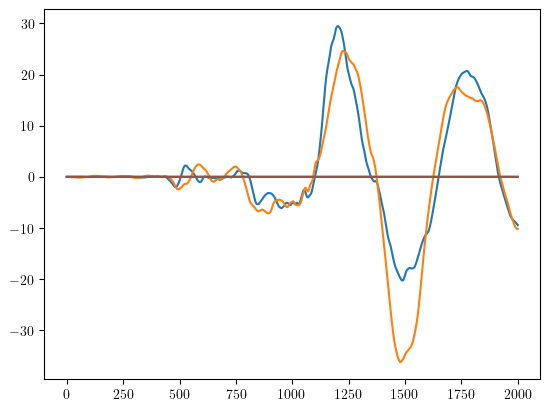

In [5]:

import matplotlib.pyplot as plt

element = "forceBeamColumn"
model = create_model(element)
displacements = analyze(model)

u3 = displacements[9]
plt.plot(u3);